# Predictive Maintenance: Clustering + Failure Classification

**Goal.** Given sensor readings from industrial machines, (1) discover typical operating
regimes via clustering, and (2) predict whether a machine will fail, using the discovered
regime as an extra feature for the classifier.

**Dataset.** [AI4I 2020 Predictive Maintenance Dataset](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset)
(UCI Machine Learning Repository) — 10,000 synthetic-but-realistic records of machine operating
conditions and whether a failure occurred.

**Pipeline.** EDA -> cleaning -> encoding -> train/test split -> scaling -> clustering (KMeans)
-> cluster interpretation -> classification (Random Forest) using cluster membership as a feature
-> model persistence.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay
from sklearn.ensemble import RandomForestClassifier
import joblib

RANDOM_STATE = 42


C:\Users\gheor\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


## 1. Load & explore

In [2]:
df = pd.read_csv('data/ai4i2020.csv')
print(df.shape)
df.head()


(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [4]:
df.isna().sum()


UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [5]:
df['Machine failure'].value_counts()


Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure rate: 3.39%


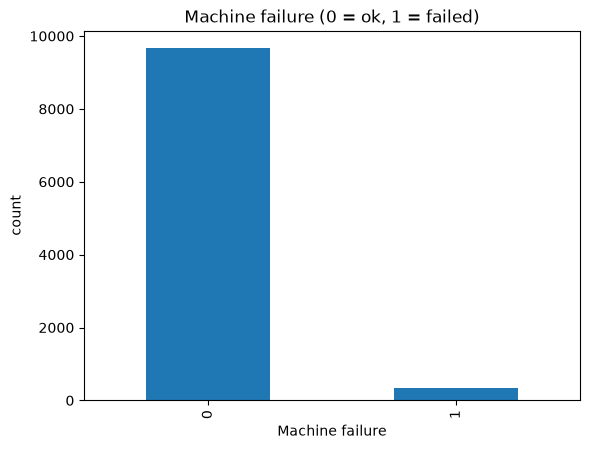

In [6]:
failure_rate = df['Machine failure'].mean()
print(f"Failure rate: {failure_rate:.2%}")

df['Machine failure'].value_counts().plot(kind='bar', title='Machine failure (0 = ok, 1 = failed)')
plt.ylabel('count')
plt.show()


The target is strongly **imbalanced** (~3.4% failures). This matters later: plain accuracy
would be misleading (predicting "never fails" would already score ~97%), so the classifier needs
`class_weight='balanced'` and we must read precision/recall/F1 on the failure class, not just
accuracy.

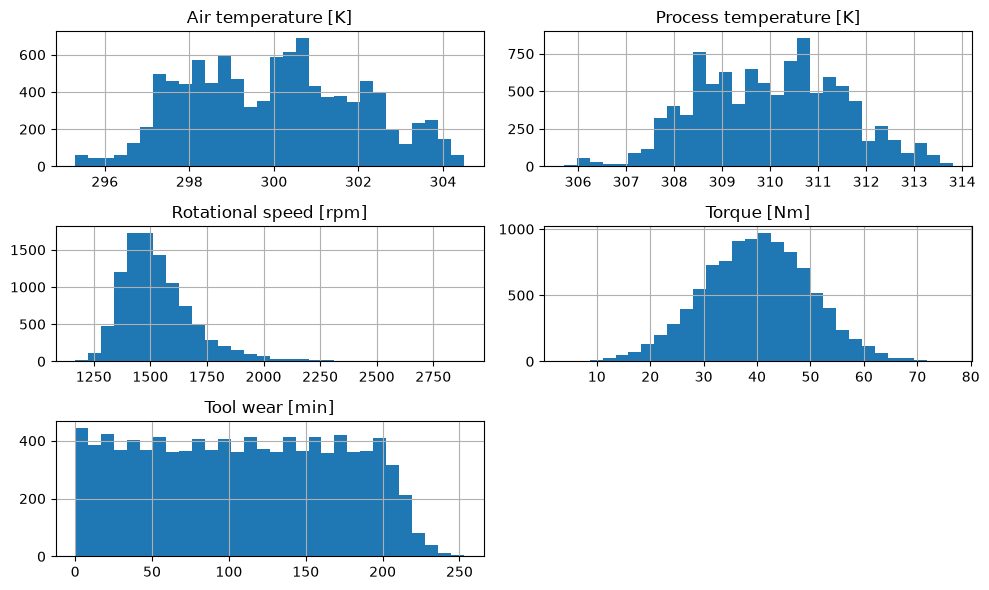

In [7]:
df[['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]',
    'Torque [Nm]', 'Tool wear [min]']].hist(figsize=(10, 6), bins=30)
plt.tight_layout()
plt.show()


In [8]:
numeric_cols = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]',
                'Torque [Nm]', 'Tool wear [min]']
df[numeric_cols].corr()


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Air temperature [K],1.000000,0.876107,0.022670,-0.013778,0.013853
Process temperature [K],0.876107,1.000000,0.019277,-0.014061,0.013488
Rotational speed [rpm],0.022670,0.019277,1.000000,-0.875027,0.000223
Torque [Nm],-0.013778,-0.014061,-0.875027,1.000000,-0.003093
Tool wear [min],0.013853,0.013488,0.000223,-0.003093,1.000000


## 2. Cleaning

- `UDI` and `Product ID` are row identifiers — no predictive value, same kind of leakage risk as an
  `Unnamed: 0` column.
- `TWF`, `HDF`, `PWF`, `OSF`, `RNF` are **failure-mode flags**: each one is already a sub-type of
  `Machine failure` (their OR is basically the target itself). Keeping them would be direct target
  leakage, so they're dropped along with the ids.


In [9]:
df = df.drop(columns=['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'])
df.head()


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


## 3. Encoding

`Type` (L / M / H) is the product quality variant — treated as ordinal (low < medium < high).

In [10]:
df['Type'].value_counts()


Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

In [11]:
encoder = OrdinalEncoder(categories=[['L', 'M', 'H']])
df['Type_enc'] = encoder.fit_transform(df[['Type']])
df[['Type', 'Type_enc']].head()


,Type,Type_enc
0,M,1.0
1,L,0.0
2,L,0.0
3,L,0.0
4,L,0.0


## 4. Train/test split

Split **before** scaling and clustering, to avoid any leakage from test data into the
preprocessing (`stratify=y` keeps the same ~3.4% failure rate in both splits, important given
the imbalance).

In [12]:
X = df[numeric_cols + ['Type_enc']]
y = df['Machine failure']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
X_train.shape, X_test.shape


((7500, 6), (2500, 6))

## 5. Scaling

Fit the scaler on the train set only, then transform both — fitting on the full dataset (as the
course templates do) would leak test-set statistics into training.

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled = scaler.transform(X_test[numeric_cols])


## 6. Clustering: discovering operating regimes

KMeans on the scaled sensor readings (temperature, speed, torque, tool wear) — not on `Type` or
the target, since the goal is to find regimes from how the machine is *running*.

Choosing `k` via silhouette score, same approach as in the clustering practice notebooks.

2 0.259
3 0.261
4 0.237
5 0.225
6 0.221


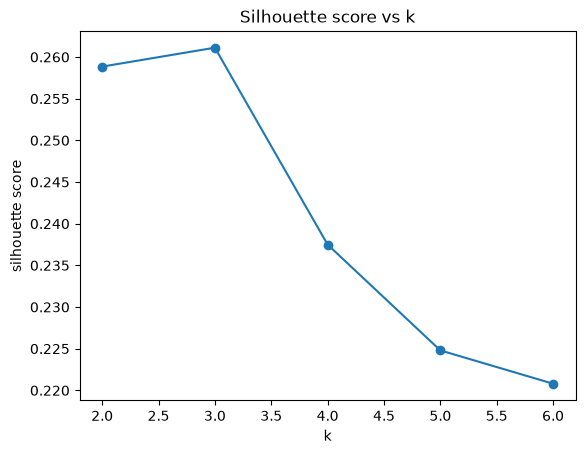

In [14]:
silhouette_scores = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_train_scaled)
    silhouette_scores[k] = silhouette_score(X_train_scaled, labels)

for k, s in silhouette_scores.items():
    print(k, round(s, 3))

plt.plot(list(silhouette_scores.keys()), list(silhouette_scores.values()), marker='o')
plt.xlabel('k')
plt.ylabel('silhouette score')
plt.title('Silhouette score vs k')
plt.show()


In [15]:
best_k = max(silhouette_scores, key=silhouette_scores.get)
print('best_k =', best_k)

kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
cluster_train = kmeans.fit_predict(X_train_scaled)
cluster_test = kmeans.predict(X_test_scaled)


best_k = 3


### Interpreting the clusters

Looking at the *original* (unscaled) feature means per cluster to describe each regime in plain
terms.

In [16]:
profile = X_train[numeric_cols].copy()
profile['cluster'] = cluster_train

cluster_means = profile.groupby('cluster').mean().round(1)
cluster_counts = profile['cluster'].value_counts().sort_index()

display(cluster_means)
display(cluster_counts)


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
cluster,,,,,
0,298.3,308.7,1473.6,43.3,104.2
1,300.2,310.1,1794.7,26.7,108.7
2,301.7,311.3,1468.5,43.7,110.5


cluster
0    3010
1    1586
2    2904
Name: count, dtype: int64

Typical pattern found: one cluster is a **high-speed / low-torque** regime (rotational speed
and torque trade off, consistent with roughly constant mechanical power), while the others are
**low-speed / high-torque** regimes that mainly differ by temperature and tool wear — one running
hotter with more worn tools than the other. These read as genuinely different operating
conditions, not arbitrary splits.

## 7. Classification: predicting failure

The cluster label is added as a one-hot feature: the hypothesis is that failure risk depends not
just on raw sensor values but on *which regime* the machine is operating in.

`class_weight='balanced'` compensates for the 3.4% failure rate — without it the model could just
predict "no failure" and still look accurate.

In [17]:
cluster_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
cluster_train_oh = cluster_encoder.fit_transform(cluster_train.reshape(-1, 1))
cluster_test_oh = cluster_encoder.transform(cluster_test.reshape(-1, 1))

X_train_final = np.hstack([X_train_scaled, X_train[['Type_enc']].values, cluster_train_oh])
X_test_final = np.hstack([X_test_scaled, X_test[['Type_enc']].values, cluster_test_oh])

X_train_final.shape, X_test_final.shape


((7500, 9), (2500, 9))

In [18]:
clf = RandomForestClassifier(
    n_estimators=200, class_weight='balanced', random_state=RANDOM_STATE
)
clf.fit(X_train_final, y_train)

y_pred = clf.predict(X_test_final)
y_proba = clf.predict_proba(X_test_final)[:, 1]


In [19]:
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print('Confusion matrix:')
print(cm)

print('ROC-AUC:', round(roc_auc_score(y_test, y_proba), 3))


              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2415
           1       0.75      0.72      0.73        85

    accuracy                           0.98      2500
   macro avg       0.87      0.85      0.86      2500
weighted avg       0.98      0.98      0.98      2500

Confusion matrix:
[[2395   20]
 [  24   61]]
ROC-AUC: 0.971


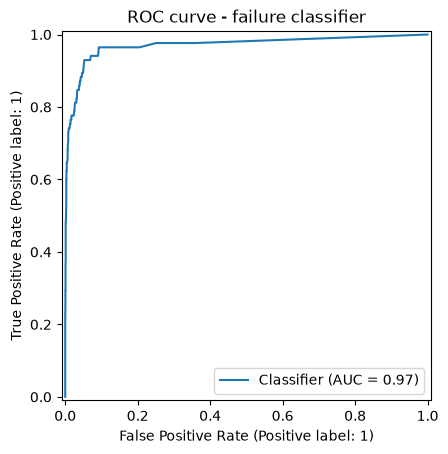

In [20]:
RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title('ROC curve - failure classifier')
plt.show()


## 8. Conclusions

- Clustering surfaced physically meaningful operating regimes (speed/torque trade-off, plus a
  hotter/more-worn-tools group) directly from unlabeled sensor data.
- The failure classifier reaches a strong ROC-AUC despite the heavy class imbalance, by using
  `class_weight='balanced'` and reading recall/precision on the minority (failure) class rather
  than accuracy alone.
- The two tasks are connected, not run side by side: the unsupervised regime assignment becomes
  an input feature for the supervised model, mirroring how segmentation output feeds downstream
  predictive models in real pipelines.


## 9. Saving the model

Persisting every fitted component needed to score new data: encoder, scaler, kmeans model,
cluster one-hot encoder, and the classifier.

In [21]:
joblib.dump(
    {
        'type_encoder': encoder,
        'scaler': scaler,
        'kmeans': kmeans,
        'cluster_encoder': cluster_encoder,
        'classifier': clf,
        'numeric_cols': numeric_cols,
    },
    'model.pkl'
)
print('Saved model.pkl')


Saved model.pkl
